# Desafio E — Concentração das compras por órgão



## 1. Título provisório

**Concentração das contratações públicas por órgão comprador no estado de São Paulo**

## 2. Problema de pesquisa

As compras públicas não necessariamente se distribuem de forma equilibrada entre os órgãos. Alguns compradores podem aparecer muitas vezes na base, enquanto outros realizam poucas contratações no mesmo intervalo.

O problema investigado é saber se, no recorte definido, as contratações estão espalhadas entre vários órgãos ou concentradas em um grupo pequeno de compradores.

Essa análise é relevante porque mostra quais órgãos aparecem com maior peso na demanda pública e evita interpretar apenas valores absolutos sem considerar a participação de cada comprador no total.

## 3. Pergunta de pesquisa

**Em que medida as contratações públicas analisadas estão concentradas nos principais órgãos compradores?**

Para responder à pergunta principal, também serão observadas três questões:

- quais órgãos possuem mais contratações;
- qual parcela do total pertence aos dez principais órgãos;
- se a concentração muda entre os dois períodos analisados.

## 4. Hipótese

Nossa expectativa inicial é que as contratações não estejam distribuídas de maneira uniforme. A hipótese adotada é que os dez órgãos com maior número de registros concentrem mais de 50% das contratações em pelo menos um dos períodos.

Essa hipótese será avaliada pelo **CR10**, que representa a participação percentual acumulada dos dez maiores órgãos. O **HHI** será utilizado como medida complementar, pois considera a participação de todos os órgãos.

## 5. Fonte dos dados

Os dados vêm da **API de Dados Abertos do Compras.gov.br**, no módulo de contratações vinculadas à Lei nº 14.133/2021.

- Documentação: https://dadosabertos.compras.gov.br/swagger-ui/index.html
- Portal: https://dados.gov.br/dados/conjuntos-dados/compras-publicas-do-governo-federal

A unidade de análise é uma contratação identificada pelo campo `idCompra`. A data da execução também será registrada, porque a base pode receber atualizações.

In [1]:
from pathlib import Path
from datetime import datetime
import time
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PASTA_DADOS = Path("dados_desafio_e")
PASTA_DADOS.mkdir(exist_ok=True)

DATA_EXECUCAO = datetime.now().strftime("%d/%m/%Y %H:%M")
print("Execução iniciada em:", DATA_EXECUCAO)

Execução iniciada em: 16/09/2026 21:04


## 6. Endpoint(s) utilizado(s)

Foi utilizado um único endpoint, suficiente para recuperar os dados das contratações e a identificação do órgão responsável:

```text
GET /modulo-contratacoes/1_consultarContratacoes_PNCP_14133
```

In [2]:
BASE_URL = "https://dadosabertos.compras.gov.br"
ENDPOINT = "/modulo-contratacoes/1_consultarContratacoes_PNCP_14133"
URL = BASE_URL + ENDPOINT

print(URL)

https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133


## 7. Parâmetros da API

Os dois períodos usam os mesmos filtros. Foi selecionado o estado de São Paulo (`SP`) e a modalidade 5, correspondente a pregão. O tamanho de página foi definido como 500, que é o limite informado na documentação da API e reduz a quantidade de requisições.

| Parâmetro | Valor | Finalidade |
|---|---:|---|
| `tamanhoPagina` | 500 | número de registros por página |
| `codigoModalidade` | 5 | pregão |
| `unidadeOrgaoUfSigla` | SP | unidades compradoras do estado de São Paulo |
| `dataPublicacaoPncpInicial` | varia por período | início do intervalo |
| `dataPublicacaoPncpFinal` | varia por período | fim do intervalo |
| `pagina` | automática | controle da paginação |

In [3]:
PARAMETROS = {
    "periodo_1": {
        "tamanhoPagina": 500,
        "dataPublicacaoPncpInicial": "2025-05-01",
        "dataPublicacaoPncpFinal": "2025-05-15",
        "codigoModalidade": 5,
        "unidadeOrgaoUfSigla": "SP",
    },
    "periodo_2": {
        "tamanhoPagina": 500,
        "dataPublicacaoPncpInicial": "2025-05-16",
        "dataPublicacaoPncpFinal": "2025-05-30",
        "codigoModalidade": 5,
        "unidadeOrgaoUfSigla": "SP",
    },
}

ROTULOS_PERIODOS = {
    "periodo_1": "01 a 15/05/2025",
    "periodo_2": "16 a 30/05/2025",
}

PARAMETROS

{'periodo_1': {'tamanhoPagina': 500,
  'dataPublicacaoPncpInicial': '2025-05-01',
  'dataPublicacaoPncpFinal': '2025-05-15',
  'codigoModalidade': 5,
  'unidadeOrgaoUfSigla': 'SP'},
 'periodo_2': {'tamanhoPagina': 500,
  'dataPublicacaoPncpInicial': '2025-05-16',
  'dataPublicacaoPncpFinal': '2025-05-30',
  'codigoModalidade': 5,
  'unidadeOrgaoUfSigla': 'SP'}}

## 8. Período analisado

Foram escolhidos dois intervalos consecutivos com a mesma duração:

- **Período 1:** 1º a 15 de maio de 2025;
- **Período 2:** 16 a 30 de maio de 2025.

O dia 31 não foi incluído para manter os dois recortes com quinze dias. Assim, a comparação não fica influenciada por uma diferença no tamanho dos períodos.

## 9. Código de coleta

A coleta percorre todas as páginas informadas pela API. Também foi configurada uma tentativa automática em caso de falha temporária. Depois da primeira execução, os dados brutos são salvos em CSV e podem ser reutilizados, evitando novas consultas desnecessárias.

In [24]:
def criar_sessao():
    estrategia = Retry(
        total=3,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
    )
    sessao = requests.Session()
    sessao.mount("https://", HTTPAdapter(max_retries=estrategia))
    return sessao


def extrair_registros(resposta_json):
    if isinstance(resposta_json, list):
        return resposta_json

    if not isinstance(resposta_json, dict):
        return []

    for chave in ["resultado", "resultados", "data", "content"]:
        registros = resposta_json.get(chave)
        if isinstance(registros, list):
            return registros

    return []


def requisitar_pagina(sessao, parametros, pagina):
    params = parametros.copy()
    params["pagina"] = pagina

    resposta = sessao.get(URL, params=params, timeout=90)
    resposta.raise_for_status()
    return resposta.json()

In [25]:
def coletar_periodo(chave_periodo, reutilizar_cache=True):
    arquivo = PASTA_DADOS / f"dados_brutos_{chave_periodo}.csv"
    rotulo = ROTULOS_PERIODOS[chave_periodo]

    if reutilizar_cache and arquivo.exists():
        print(f"{rotulo}: leitura do arquivo local")
        return pd.read_csv(
            arquivo,
            dtype={
                "idCompra": "string",
                "numeroControlePNCP": "string",
                "orgaoEntidadeCnpj": "string",
                "codigoOrgao": "string",
                "unidadeOrgaoCodigoUnidade": "string",
            },
        )

    parametros = PARAMETROS[chave_periodo]
    sessao = criar_sessao()

    primeira_resposta = requisitar_pagina(sessao, parametros, pagina=1)
    registros = extrair_registros(primeira_resposta)

    total_paginas = primeira_resposta.get("totalPaginas")
    total_registros = primeira_resposta.get("totalRegistros")

    if total_paginas is None:
        raise RuntimeError("A API não informou o total de páginas.")

    print(
        f"{rotulo}: {total_registros} registros em "
        f"{total_paginas} página(s)"
    )

    for pagina in range(2, int(total_paginas) + 1):
        resposta_json = requisitar_pagina(sessao, parametros, pagina)
        novos = extrair_registros(resposta_json)

        if not novos:
            raise RuntimeError(
                f"A página {pagina} veio vazia antes do fim da coleta."
            )

        registros.extend(novos)
        print(f"  página {pagina}/{total_paginas}: {len(novos)} registros")
        time.sleep(0.2)

    df_periodo = pd.json_normalize(registros)
    df_periodo["periodo"] = rotulo
    df_periodo["data_coleta"] = DATA_EXECUCAO

    if total_registros is not None and len(df_periodo) != int(total_registros):
        raise RuntimeError(
            "Quantidade coletada diferente do total informado pela API: "
            f"{len(df_periodo)} de {total_registros}."
        )

    df_periodo.to_csv(arquivo, index=False, encoding="utf-8-sig")
    return df_periodo

In [6]:
df_periodo_1 = coletar_periodo("periodo_1")
df_periodo_2 = coletar_periodo("periodo_2")

print("\nDimensão do período 1:", df_periodo_1.shape)
print("Dimensão do período 2:", df_periodo_2.shape)

01 a 15/05/2025: 1429 registros em 3 página(s)
  página 2/3: 500 registros
  página 3/3: 429 registros
16 a 30/05/2025: 1684 registros em 4 página(s)
  página 2/4: 500 registros
  página 3/4: 500 registros
  página 4/4: 184 registros

Dimensão do período 1: (1429, 54)
Dimensão do período 2: (1684, 54)


## 10. Construção do DataFrame

Os dois conjuntos foram unidos em um único `DataFrame`. Foram mantidas apenas as variáveis necessárias para identificar a contratação, o órgão, o período e os valores monetários.

In [7]:
df_bruto = pd.concat(
    [df_periodo_1, df_periodo_2],
    ignore_index=True,
    sort=False,
)

colunas_interesse = [
    "idCompra",
    "numeroControlePNCP",
    "orgaoEntidadeCnpj",
    "codigoOrgao",
    "orgaoEntidadeRazaoSocial",
    "orgaoEntidadeEsferaId",
    "unidadeOrgaoCodigoUnidade",
    "unidadeOrgaoNomeUnidade",
    "unidadeOrgaoUfSigla",
    "modalidadeNome",
    "valorTotalEstimado",
    "valorTotalHomologado",
    "dataPublicacaoPncp",
    "contratacaoExcluida",
    "periodo",
    "data_coleta",
]

colunas_ausentes = [c for c in colunas_interesse if c not in df_bruto.columns]
if colunas_ausentes:
    raise KeyError(f"Colunas esperadas não encontradas: {colunas_ausentes}")

df_analise = df_bruto[colunas_interesse].copy()

print("Dimensão inicial:", df_analise.shape)
display(df_analise.head())

Dimensão inicial: (3113, 16)


,idCompra,numeroControlePNCP,orgaoEntidadeCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoEntidadeEsferaId,unidadeOrgaoCodigoUnidade,unidadeOrgaoNomeUnidade,unidadeOrgaoUfSigla,modalidadeNome,valorTotalEstimado,valorTotalHomologado,dataPublicacaoPncp,contratacaoExcluida,periodo,data_coleta
0,92967905900012025,48198725000162-1-000052/2025,48198725000162,83589,CAMARA MUNICIPAL DE MOGI GUACU,M,929679,CAMARA MUNICIPAL DE MOJI-GUACU - SP,SP,Pregão - Eletrônico,"293,237.06","288,069.00",2025-05-02T07:16:01,False,01 a 15/05/2025,16/09/2026 21:04
1,09013305900682025,46374500000194-1-003439/2025,46374500000194,34952,SECRETARIA DE ESTADO DA SAUDE,E,090133,ESP-DEPTO.REG.SAUDE - DRS-XIV SJBOA VISTA,SP,Pregão - Eletrônico,"91,698.92","7,525.40",2025-05-02T07:16:21,False,01 a 15/05/2025,16/09/2026 21:04
2,18015805900142025,46377800000127-1-001783/2025,46377800000127,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,E,180158,ESP-COM.POL.INT.3(CPI-3-CEL.PAULO M.SERRAT FI,SP,Pregão - Eletrônico,"52,245.06","44,000.00",2025-05-02T07:16:35,False,01 a 15/05/2025,16/09/2026 21:04
3,53210105907532025,60747318000162-1-000718/2025,60747318000162,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,E,532101,ESP-INST. ASSIST. MEDICA SERV. PUB. ESTADUAL,SP,Pregão - Eletrônico,"385,875.75","174,300.00",2025-05-02T07:16:43,False,01 a 15/05/2025,16/09/2026 21:04
4,53210105907542025,60747318000162-1-000719/2025,60747318000162,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,E,532101,ESP-INST. ASSIST. MEDICA SERV. PUB. ESTADUAL,SP,Pregão - Eletrônico,"577,107.45","275,745.00",2025-05-02T07:17:01,False,01 a 15/05/2025,16/09/2026 21:04


## 11. Avaliação da qualidade dos dados

Antes da limpeza, foram verificados duplicidades, valores ausentes, tipos de dados e registros marcados como excluídos. Essa etapa ajuda a documentar o que realmente foi alterado.

In [8]:
resumo_qualidade = pd.DataFrame({
    "tipo": df_analise.dtypes.astype(str),
    "ausentes": df_analise.isna().sum(),
    "ausentes_%": df_analise.isna().mean().mul(100),
    "valores_unicos": df_analise.nunique(dropna=True),
}).sort_values("ausentes_%", ascending=False)

print("Linhas completamente duplicadas:", df_analise.duplicated().sum())
print("IDs de compra duplicados:", df_analise["idCompra"].duplicated().sum())
print(
    "Contratações marcadas como excluídas:",
    df_analise["contratacaoExcluida"].fillna(False).astype(bool).sum(),
)

display(resumo_qualidade)

Linhas completamente duplicadas: 0
IDs de compra duplicados: 0
Contratações marcadas como excluídas: 0


,tipo,ausentes,ausentes_%,valores_unicos
valorTotalHomologado,float64,476,15.29,2553
idCompra,str,0,0.00,3113
orgaoEntidadeCnpj,str,0,0.00,212
numeroControlePNCP,str,0,0.00,3113
orgaoEntidadeRazaoSocial,str,0,0.00,210
orgaoEntidadeEsferaId,str,0,0.00,4
unidadeOrgaoCodigoUnidade,str,0,0.00,574
codigoOrgao,int64,0,0.00,212
unidadeOrgaoNomeUnidade,str,0,0.00,574
unidadeOrgaoUfSigla,str,0,0.00,1


In [9]:
for coluna in ["valorTotalEstimado", "valorTotalHomologado"]:
    valores = pd.to_numeric(df_analise[coluna], errors="coerce")
    print(
        f"{coluna}: {valores.isna().sum()} ausentes, "
        f"{(valores < 0).sum()} negativos e {(valores == 0).sum()} iguais a zero"
    )

valorTotalEstimado: 0 ausentes, 0 negativos e 298 iguais a zero
valorTotalHomologado: 476 ausentes, 0 negativos e 0 iguais a zero


## 12. Limpeza

Foram adotados os seguintes critérios:

1. excluir registros marcados pela própria base como contratação excluída;
2. retirar duplicidades pelo `idCompra`;
3. padronizar CNPJ e nome do órgão;
4. converter datas e valores para os tipos adequados;
5. transformar valores monetários negativos em ausentes, sem eliminar valores iguais a zero;
6. excluir somente os registros sem qualquer identificação utilizável do órgão.

O CNPJ foi escolhido como identificador principal. Quando ele não existe, o código do órgão ou o nome padronizado é usado como alternativa.

In [10]:
df_limpo = df_analise.copy()
linhas_iniciais = len(df_limpo)

df_limpo["contratacaoExcluida"] = (
    df_limpo["contratacaoExcluida"]
    .fillna(False)
    .astype(bool)
)
df_limpo = df_limpo.loc[~df_limpo["contratacaoExcluida"]].copy()

df_limpo = df_limpo.drop_duplicates(subset="idCompra", keep="first")

df_limpo["orgao_nome"] = (
    df_limpo["orgaoEntidadeRazaoSocial"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.upper()
)

df_limpo["orgao_cnpj"] = (
    df_limpo["orgaoEntidadeCnpj"]
    .astype("string")
    .str.replace(r"\D", "", regex=True)
    .replace("", pd.NA)
)

df_limpo["codigoOrgao"] = (
    df_limpo["codigoOrgao"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

df_limpo["orgao_id"] = np.select(
    [
        df_limpo["orgao_cnpj"].notna(),
        df_limpo["codigoOrgao"].notna(),
        df_limpo["orgao_nome"].notna(),
    ],
    [
        "CNPJ:" + df_limpo["orgao_cnpj"].fillna(""),
        "COD:" + df_limpo["codigoOrgao"].fillna(""),
        "NOME:" + df_limpo["orgao_nome"].fillna(""),
    ],
    default="",
)

for coluna in ["valorTotalEstimado", "valorTotalHomologado"]:
    df_limpo[coluna] = pd.to_numeric(df_limpo[coluna], errors="coerce")
    df_limpo.loc[df_limpo[coluna] < 0, coluna] = np.nan

df_limpo["dataPublicacaoPncp"] = pd.to_datetime(
    df_limpo["dataPublicacaoPncp"], errors="coerce"
)

df_limpo = df_limpo.loc[
    df_limpo["orgao_id"].ne("") & df_limpo["orgao_nome"].notna()
].copy()

df_limpo.to_csv(
    PASTA_DADOS / "dados_tratados_desafio_e.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Linhas antes da limpeza:", linhas_iniciais)
print("Linhas depois da limpeza:", len(df_limpo))
print("Linhas removidas:", linhas_iniciais - len(df_limpo))

Linhas antes da limpeza: 3113
Linhas depois da limpeza: 3113
Linhas removidas: 0


In [11]:
validacao_limpeza = pd.Series({
    "ids_duplicados": df_limpo["idCompra"].duplicated().sum(),
    "orgaos_sem_id": df_limpo["orgao_id"].eq("").sum(),
    "nomes_ausentes": df_limpo["orgao_nome"].isna().sum(),
    "datas_invalidas": df_limpo["dataPublicacaoPncp"].isna().sum(),
    "valores_estimados_negativos": (df_limpo["valorTotalEstimado"] < 0).sum(),
})

display(validacao_limpeza.to_frame("quantidade"))

,quantidade
ids_duplicados,0
orgaos_sem_id,0
nomes_ausentes,0
datas_invalidas,0
valores_estimados_negativos,0


## 13. Estatística descritiva

A concentração principal foi calculada pela **quantidade de contratações**. Também foi feita uma análise financeira com o valor total estimado, mas ela deve ser interpretada separadamente porque algumas contratações podem ter valor ausente ou igual a zero.

In [12]:
def montar_ranking_quantidade(dados):
    total = len(dados)
    ranking = (
        dados.groupby("orgao_id", as_index=False)
        .agg(
            orgao_nome=("orgao_nome", "first"),
            quantidade_contratacoes=("idCompra", "nunique"),
        )
        .sort_values("quantidade_contratacoes", ascending=False)
        .reset_index(drop=True)
    )
    ranking["participacao_%"] = (
        ranking["quantidade_contratacoes"].div(total).mul(100)
    )
    ranking["participacao_acumulada_%"] = ranking["participacao_%"].cumsum()
    return ranking


ranking_geral = montar_ranking_quantidade(df_limpo)
total_contratacoes = df_limpo["idCompra"].nunique()
total_orgaos = df_limpo["orgao_id"].nunique()
cr10_geral = ranking_geral.head(10)["participacao_%"].sum()
hhi_geral = ((ranking_geral["participacao_%"] / 100) ** 2).sum()
orgaos_ate_80 = int((ranking_geral["participacao_acumulada_%"] < 80).sum() + 1)

resumo_geral = pd.Series({
    "Contratações analisadas": total_contratacoes,
    "Órgãos distintos": total_orgaos,
    "Média de contratações por órgão": ranking_geral["quantidade_contratacoes"].mean(),
    "Mediana de contratações por órgão": ranking_geral["quantidade_contratacoes"].median(),
    "CR10 (%)": cr10_geral,
    "HHI (0 a 1)": hhi_geral,
    "Órgãos necessários para alcançar 80%": orgaos_ate_80,
})

display(resumo_geral.to_frame("resultado"))
print(f"HHI geral com quatro casas decimais: {hhi_geral:.4f}")
display(ranking_geral.head(10))

,resultado
Contratações analisadas,"3,113.00"
Órgãos distintos,212.00
Média de contratações por órgão,14.68
Mediana de contratações por órgão,2.50
CR10 (%),65.24
HHI (0 a 1),0.10
Órgãos necessários para alcançar 80%,29.00


HHI geral com quatro casas decimais: 0.0960


,orgao_id,orgao_nome,quantidade_contratacoes,participacao_%,participacao_acumulada_%
0,CNPJ:46374500000194,SECRETARIA DE ESTADO DA SAUDE,842,27.05,27.05
1,CNPJ:46377800000127,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,286,9.19,36.24
2,CNPJ:60747318000162,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,205,6.59,42.82
3,CNPJ:63025530000104,UNIVERSIDADE DE SAO PAULO,171,5.49,48.31
4,CNPJ:96291141000180,SAO PAULO SECRETARIA DA ADMINISTRACAO PENITENC...,124,3.98,52.30
5,CNPJ:13864377000130,FUNDO MUNICIPAL DE SAUDE - FMS,118,3.79,56.09
6,CNPJ:60448040000122,HOSPITAL DAS CLINICAS DA FACULDADE DE MEDICINA...,106,3.41,59.49
7,CNPJ:46137410000180,MUNICIPIO DE BAURU,62,1.99,61.48
8,CNPJ:48031918000124,UNIVERSIDADE ESTADUAL PAULISTA JULIO DE MESQUI...,59,1.90,63.38
9,CNPJ:56023443000152,HOSPITAL DAS CLINICAS DA FACULDADE DE MEDICINA...,58,1.86,65.24


In [13]:
estatisticas_valores = (
    df_limpo[["valorTotalEstimado", "valorTotalHomologado"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T
)

display(estatisticas_valores)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
valorTotalEstimado,"3,113.00","1,259,629.06","8,133,020.57",0.00,"17,588.11","99,176.00","421,700.20","1,587,875.33","3,929,521.08","20,726,981.53","256,866,912.33"
valorTotalHomologado,"2,637.00","970,899.97","6,761,737.84",0.00,"18,533.42","79,200.00","304,015.67","1,071,518.20","2,674,685.98","17,041,195.20","228,611,551.97"


In [14]:
valores_validos = df_limpo["valorTotalEstimado"].dropna()
q1 = valores_validos.quantile(0.25)
q3 = valores_validos.quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

valores_extremos = df_limpo.loc[
    df_limpo["valorTotalEstimado"] > limite_superior,
    ["idCompra", "orgao_nome", "valorTotalEstimado", "periodo"],
].sort_values("valorTotalEstimado", ascending=False)

print(f"Limite superior pelo critério do IQR: R$ {limite_superior:,.2f}")
print("Registros acima do limite:", len(valores_extremos))
display(valores_extremos.head(10))

Limite superior pelo critério do IQR: R$ 1,027,868.33
Registros acima do limite: 404


,idCompra,orgao_nome,valorTotalEstimado,periodo
252,53320105900322025,(UO) ESP-PRODESP-CIA.PROC DE DADOS EST. SP,"256,866,912.33",01 a 15/05/2025
297,53320105900342025,(UO) ESP-PRODESP-CIA.PROC DE DADOS EST. SP,"185,026,874.64",01 a 15/05/2025
2953,92649505900902025,SAO PAULO TRIBUNAL DE JUSTICA,"141,711,546.00",16 a 30/05/2025
1421,53210105908932025,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,"96,912,792.00",01 a 15/05/2025
1590,92500305905172025,FUNDO MUNICIPAL DE SAUDE - FMS,"91,558,116.00",16 a 30/05/2025
2091,80308005903532025,SERVICO FEDERAL DE PROCESSAMENTO DE DADOS (SER...,"86,148,830.94",16 a 30/05/2025
3066,98692105900682025,MUNICIPIO DE PRAIA GRANDE,"80,087,119.50",16 a 30/05/2025
1099,92500305904852025,FUNDO MUNICIPAL DE SAUDE - FMS,"69,889,831.68",01 a 15/05/2025
2515,16049105900022025,COMANDO DO EXERCITO,"67,182,359.00",16 a 30/05/2025
1962,18021605900022025,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,"64,724,604.00",16 a 30/05/2025


Os valores acima do limite do IQR foram examinados, mas não removidos automaticamente. Em compras públicas, uma contratação de grande porte pode ser verdadeira e relevante. Além disso, a medida principal deste estudo é a quantidade de contratações, não a média dos valores.

In [15]:
ranking_valor = (
    df_limpo.groupby("orgao_id", as_index=False)
    .agg(
        orgao_nome=("orgao_nome", "first"),
        valor_estimado_total=("valorTotalEstimado", "sum"),
    )
    .sort_values("valor_estimado_total", ascending=False)
    .reset_index(drop=True)
)

total_valor_estimado = ranking_valor["valor_estimado_total"].sum()
ranking_valor["participacao_valor_%"] = (
    ranking_valor["valor_estimado_total"].div(total_valor_estimado).mul(100)
)
cr10_valor = ranking_valor.head(10)["participacao_valor_%"].sum()

print(f"Valor estimado total: R$ {total_valor_estimado:,.2f}")
print(f"Participação dos 10 maiores órgãos em valor: {cr10_valor:.2f}%")
display(ranking_valor.head(10))

Valor estimado total: R$ 3,921,225,273.43
Participação dos 10 maiores órgãos em valor: 61.69%


,orgao_id,orgao_nome,valor_estimado_total,participacao_valor_%
0,CNPJ:13864377000130,FUNDO MUNICIPAL DE SAUDE - FMS,"480,951,983.62",12.27
1,CNPJ:62577929000135,(UO) ESP-PRODESP-CIA.PROC DE DADOS EST. SP,"442,187,199.57",11.28
2,CNPJ:46374500000194,SECRETARIA DE ESTADO DA SAUDE,"305,099,074.65",7.78
3,CNPJ:60747318000162,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,"230,017,467.11",5.87
4,CNPJ:51174001000193,SAO PAULO TRIBUNAL DE JUSTICA,"207,988,511.01",5.30
5,CNPJ:46377800000127,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,"186,217,294.38",4.75
6,CNPJ:00394429000100,COMANDO DA AERONAUTICA,"160,489,743.18",4.09
7,CNPJ:60448040000122,HOSPITAL DAS CLINICAS DA FACULDADE DE MEDICINA...,"153,863,843.73",3.92
8,CNPJ:46177531000155,MUNICIPIO DE PRAIA GRANDE,"147,482,890.53",3.76
9,CNPJ:00394452000103,COMANDO DO EXERCITO,"104,573,781.21",2.67


## 14. Visualizações

Os gráficos abaixo mostram o ranking dos principais órgãos, a curva de Pareto e a diferença entre a participação dos dez maiores e a dos demais compradores.

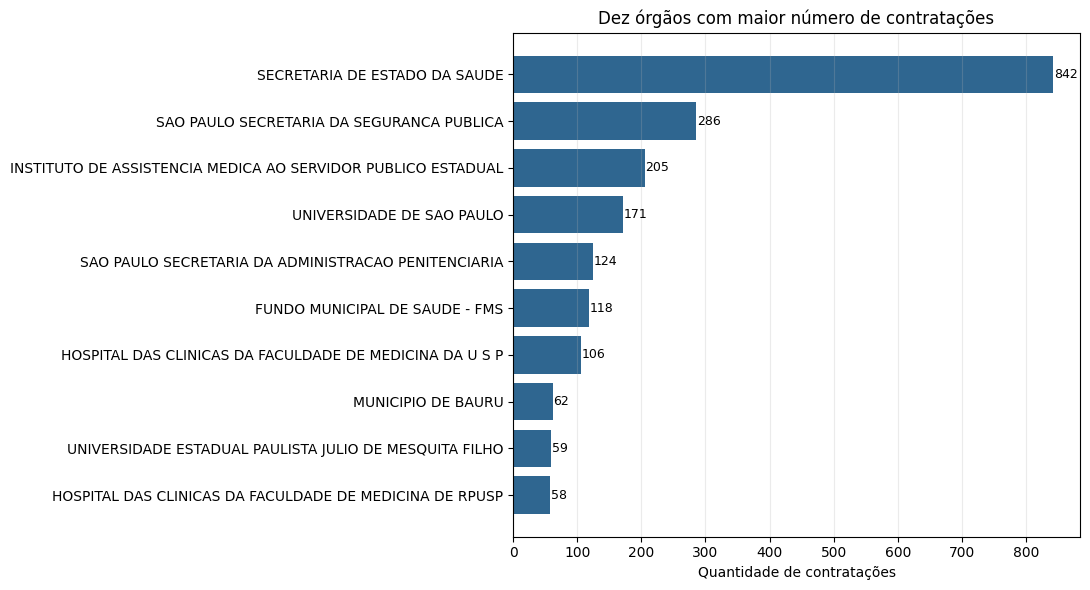

In [16]:
top10 = ranking_geral.head(10).sort_values("quantidade_contratacoes")

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10["orgao_nome"], top10["quantidade_contratacoes"], color="#2F6690")
ax.set_title("Dez órgãos com maior número de contratações")
ax.set_xlabel("Quantidade de contratações")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)

for i, valor in enumerate(top10["quantidade_contratacoes"]):
    ax.text(valor + 1, i, str(valor), va="center", fontsize=9)

plt.tight_layout()
plt.show()

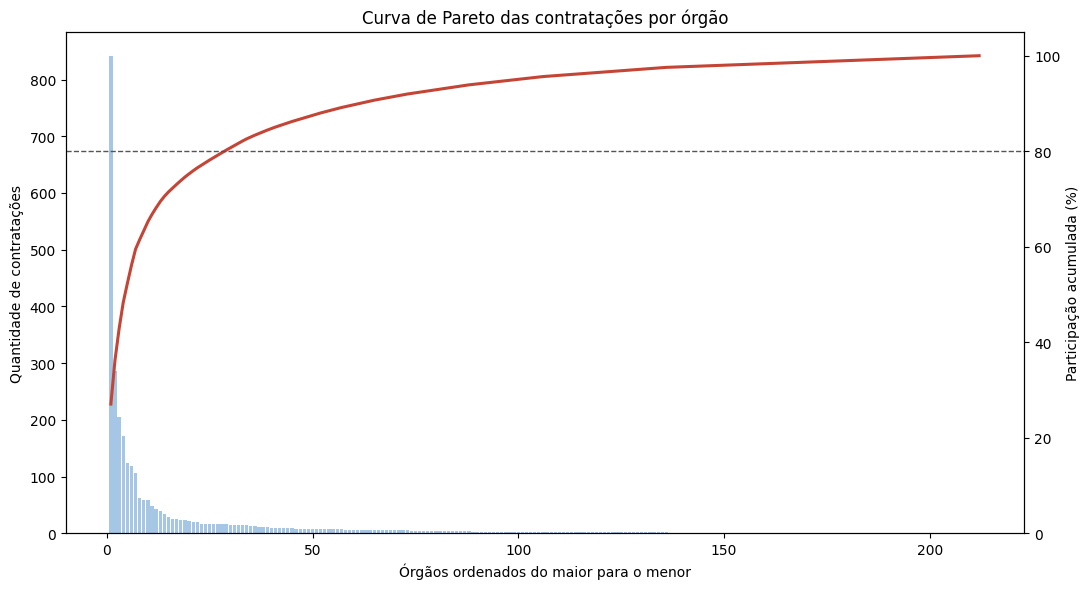

In [17]:
fig, ax1 = plt.subplots(figsize=(11, 6))
x = np.arange(1, len(ranking_geral) + 1)

ax1.bar(
    x,
    ranking_geral["quantidade_contratacoes"],
    color="#8FB8DE",
    alpha=0.8,
)
ax1.set_xlabel("Órgãos ordenados do maior para o menor")
ax1.set_ylabel("Quantidade de contratações")

ax2 = ax1.twinx()
ax2.plot(
    x,
    ranking_geral["participacao_acumulada_%"],
    color="#C44536",
    linewidth=2.2,
)
ax2.axhline(80, color="#555555", linestyle="--", linewidth=1)
ax2.set_ylabel("Participação acumulada (%)")
ax2.set_ylim(0, 105)

plt.title("Curva de Pareto das contratações por órgão")
plt.tight_layout()
plt.show()

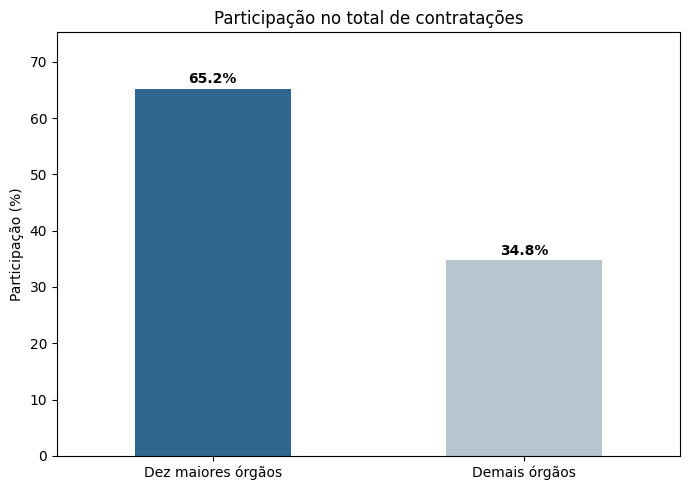

In [18]:
participacao_grupos = pd.Series({
    "Dez maiores órgãos": cr10_geral,
    "Demais órgãos": 100 - cr10_geral,
})

fig, ax = plt.subplots(figsize=(7, 5))
participacao_grupos.plot(
    kind="bar",
    color=["#2F6690", "#B8C4CE"],
    ax=ax,
)
ax.set_title("Participação no total de contratações")
ax.set_ylabel("Participação (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, max(participacao_grupos) + 10)

for i, valor in enumerate(participacao_grupos):
    ax.text(i, valor + 1, f"{valor:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 15. Comparação quantitativa

Para comparar os períodos foram calculados quatro indicadores:

- número de contratações;
- número de órgãos distintos;
- CR10, que mede a parcela dos dez maiores órgãos;
- HHI, calculado a partir da soma dos quadrados das participações de todos os órgãos.

Também foi utilizado o HHI normalizado. Essa versão facilita a comparação quando o número de órgãos não é igual nos dois períodos.

In [19]:
def calcular_indicadores_periodo(dados):
    ranking = montar_ranking_quantidade(dados)
    n_orgaos = len(ranking)
    participacoes = ranking["participacao_%"] / 100
    hhi = (participacoes ** 2).sum()

    if n_orgaos > 1:
        hhi_normalizado = (hhi - 1 / n_orgaos) / (1 - 1 / n_orgaos)
    else:
        hhi_normalizado = 1.0

    return pd.Series({
        "contratacoes": dados["idCompra"].nunique(),
        "orgaos": n_orgaos,
        "cr10_%": ranking.head(10)["participacao_%"].sum(),
        "hhi": hhi,
        "hhi_normalizado": hhi_normalizado,
    })


comparacao_periodos = (
    df_limpo.groupby("periodo", sort=False)
    .apply(calcular_indicadores_periodo, include_groups=False)
    .reset_index()
)

display(comparacao_periodos)

,periodo,contratacoes,orgaos,cr10_%,hhi,hhi_normalizado
0,01 a 15/05/2025,"1,429.00",158.00,65.43,0.10,0.09
1,16 a 30/05/2025,"1,684.00",163.00,65.44,0.10,0.09


In [20]:
p1 = comparacao_periodos.iloc[0]
p2 = comparacao_periodos.iloc[1]

diferenca_cr10 = p2["cr10_%"] - p1["cr10_%"]
diferenca_hhi_norm = p2["hhi_normalizado"] - p1["hhi_normalizado"]
variacao_contratacoes = (p2["contratacoes"] / p1["contratacoes"] - 1) * 100

comparacao_diferencas = pd.Series({
    "Variação no número de contratações (%)": variacao_contratacoes,
    "Diferença do CR10 (pontos percentuais)": diferenca_cr10,
    "Diferença do HHI normalizado": diferenca_hhi_norm,
})

print(
    comparacao_diferencas.to_frame("resultado").to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

                                        resultado
Variação no número de contratações (%)    17.8446
Diferença do CR10 (pontos percentuais)     0.0091
Diferença do HHI normalizado               0.0011


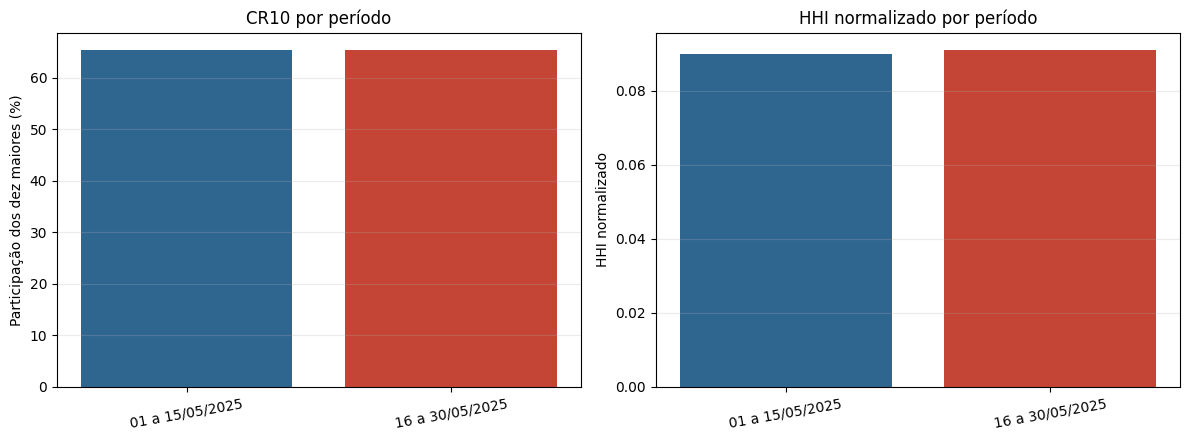

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(
    comparacao_periodos["periodo"],
    comparacao_periodos["cr10_%"],
    color=["#2F6690", "#C44536"],
)
axes[0].set_title("CR10 por período")
axes[0].set_ylabel("Participação dos dez maiores (%)")
axes[0].tick_params(axis="x", rotation=10)

axes[1].bar(
    comparacao_periodos["periodo"],
    comparacao_periodos["hhi_normalizado"],
    color=["#2F6690", "#C44536"],
)
axes[1].set_title("HHI normalizado por período")
axes[1].set_ylabel("HHI normalizado")
axes[1].tick_params(axis="x", rotation=10)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 16. Discussão

O texto abaixo é preenchido com os valores calculados. A interpretação considera o CR10 como indicador principal e o HHI normalizado como confirmação. Os resultados descrevem apenas o recorte analisado e não demonstram relação de causa e efeito.

In [22]:
if abs(diferenca_cr10) < 1:
    leitura_cr10 = "permaneceu praticamente estável"
elif diferenca_cr10 > 0:
    leitura_cr10 = "aumentou"
else:
    leitura_cr10 = "diminuiu"

if abs(diferenca_hhi_norm) < 0.005:
    leitura_hhi = "também ficou estável"
elif diferenca_hhi_norm > 0:
    leitura_hhi = "apontou aumento da concentração"
else:
    leitura_hhi = "apontou redução da concentração"

texto_discussao = (
    "### Discussão dos resultados\n\n"
    f"No primeiro período foram analisadas **{int(p1['contratacoes'])} contratações**, "
    f"distribuídas entre **{int(p1['orgaos'])} órgãos**. Os dez maiores compradores "
    f"responderam por **{p1['cr10_%']:.2f}%** dos registros.\n\n"
    f"No segundo período foram encontradas **{int(p2['contratacoes'])} contratações** "
    f"e **{int(p2['orgaos'])} órgãos**. Nesse intervalo, o CR10 foi de "
    f"**{p2['cr10_%']:.2f}%**. A diferença foi de **{diferenca_cr10:.2f} pontos "
    f"percentuais**, portanto a participação dos dez maiores {leitura_cr10}.\n\n"
    f"O HHI normalizado passou de **{p1['hhi_normalizado']:.4f}** para "
    f"**{p2['hhi_normalizado']:.4f}** e {leitura_hhi}. Como o CR10 considera somente "
    "os dez primeiros e o HHI considera todos os órgãos, a leitura conjunta evita "
    "basear a discussão em uma única medida.\n\n"
    f"No conjunto dos dois períodos, foram necessários **{orgaos_ate_80} órgãos** "
    "para alcançar 80% das contratações. Esse resultado complementa a curva de "
    "Pareto e mostra quantos compradores formam a maior parte do volume observado.\n\n"
    f"A análise por valor estimado apresentou CR10 de **{cr10_valor:.2f}%**. Esse "
    "percentual não deve ser confundido com o CR10 por quantidade: um órgão pode "
    "ter poucas contratações de valor alto ou muitas contratações de valor baixo."
)

display(Markdown(texto_discussao))

### Discussão dos resultados

No primeiro período foram analisadas **1429 contratações**, distribuídas entre **158 órgãos**. Os dez maiores compradores responderam por **65.43%** dos registros.

No segundo período foram encontradas **1684 contratações** e **163 órgãos**. Nesse intervalo, o CR10 foi de **65.44%**. A diferença foi de **0.01 pontos percentuais**, portanto a participação dos dez maiores permaneceu praticamente estável.

O HHI normalizado passou de **0.0901** para **0.0912** e também ficou estável. Como o CR10 considera somente os dez primeiros e o HHI considera todos os órgãos, a leitura conjunta evita basear a discussão em uma única medida.

No conjunto dos dois períodos, foram necessários **29 órgãos** para alcançar 80% das contratações. Esse resultado complementa a curva de Pareto e mostra quantos compradores formam a maior parte do volume observado.

A análise por valor estimado apresentou CR10 de **61.69%**. Esse percentual não deve ser confundido com o CR10 por quantidade: um órgão pode ter poucas contratações de valor alto ou muitas contratações de valor baixo.

## 17. Limitações

Esta análise possui algumas limitações:

- considera somente pregões publicados por unidades compradoras de São Paulo em dois períodos de maio de 2025;
- os resultados não representam todas as modalidades nem todo o país;
- a API pode receber correções e atualizações depois da data da coleta;
- diferenças de cadastramento podem afetar nomes e identificadores dos órgãos;
- o número de contratações e o valor financeiro medem aspectos diferentes;
- valores ausentes ou iguais a zero limitam a análise financeira;
- o estudo é descritivo e não permite afirmar por que a concentração aumentou ou diminuiu;
- CR10 e HHI resumem a distribuição, mas não substituem a leitura do ranking e dos gráficos.

Por isso, as conclusões se aplicam apenas ao recorte e aos filtros registrados neste notebook.

## 18. Conclusão

A conclusão a seguir responde diretamente à pergunta de pesquisa e informa se a hipótese inicial foi sustentada pelos dados.

In [23]:
hipotese_sustentada = (comparacao_periodos["cr10_%"] > 50).any()

if hipotese_sustentada:
    resultado_hipotese = (
        "A hipótese inicial foi sustentada, pois os dez maiores órgãos "
        "ultrapassaram 50% das contratações em pelo menos um dos períodos."
    )
else:
    resultado_hipotese = (
        "A hipótese inicial não foi sustentada, pois os dez maiores órgãos "
        "não ultrapassaram 50% das contratações em nenhum dos períodos."
    )

if diferenca_cr10 > 1:
    sintese_temporal = "houve aumento da concentração no segundo período"
elif diferenca_cr10 < -1:
    sintese_temporal = "houve redução da concentração no segundo período"
else:
    sintese_temporal = "a concentração ficou relativamente estável entre os períodos"

texto_conclusao = (
    "### Conclusão final\n\n"
    "O estudo procurou verificar em que medida as contratações públicas do recorte "
    "estavam concentradas nos principais órgãos compradores. Os resultados mostraram "
    f"CR10 de **{p1['cr10_%']:.2f}%** entre 1º e 15 de maio e de "
    f"**{p2['cr10_%']:.2f}%** entre 16 e 30 de maio de 2025.\n\n"
    f"Com uma diferença de **{diferenca_cr10:.2f} pontos percentuais**, "
    f"{sintese_temporal}. {resultado_hipotese}\n\n"
    "Assim, foi possível identificar os órgãos com maior número de contratações, "
    "calcular a participação dos dez principais compradores e comparar a distribuição "
    "entre dois períodos equivalentes. A resposta é válida para os filtros adotados "
    "e deve ser interpretada junto das limitações apresentadas."
)

display(Markdown(texto_conclusao))

### Conclusão final

O estudo procurou verificar em que medida as contratações públicas do recorte estavam concentradas nos principais órgãos compradores. Os resultados mostraram CR10 de **65.43%** entre 1º e 15 de maio e de **65.44%** entre 16 e 30 de maio de 2025.

Com uma diferença de **0.01 pontos percentuais**, a concentração ficou relativamente estável entre os períodos. A hipótese inicial foi sustentada, pois os dez maiores órgãos ultrapassaram 50% das contratações em pelo menos um dos períodos.

Assim, foi possível identificar os órgãos com maior número de contratações, calcular a participação dos dez principais compradores e comparar a distribuição entre dois períodos equivalentes. A resposta é válida para os filtros adotados e deve ser interpretada junto das limitações apresentadas.